<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [ ]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [3]:
# Display column names
print(df.columns)

# Display data types and dataset information
print(df.info())

# Display shape of dataset
print("Shape:", df.shape)

Index(['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check',
       'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline',
       ...
       'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9',
       'JobSatPoints_10', 'JobSatPoints_11', 'SurveyLength', 'SurveyEase',
       'ConvertedCompYearly', 'JobSat'],
      dtype='str', length=114)
<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.6 MB
None
Shape: (65437, 114)


### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [4]:
print(df[['Employment', 'RemoteWork', 'JobSat', 'YearsCodePro']].isnull().sum())

df['Employment'] = df['Employment'].fillna(df['Employment'].mode()[0])
df['RemoteWork'] = df['RemoteWork'].fillna(df['RemoteWork'].mode()[0])

# Drop only rows missing JobSat — don't invent satisfaction scores
df = df.dropna(subset=['JobSat'])

print("Shape:", df.shape)   # expect (29126, 114)

Employment          0
RemoteWork      10631
JobSat          36311
YearsCodePro    13827
dtype: int64
Shape: (29126, 114)


### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [5]:
print("Employment Value Counts:")
print(df['Employment'].value_counts())

print("\nJob Satisfaction Value Counts:")
print(df['JobSat'].value_counts())

print("\nYearsCodePro Value Counts:")
print(df['YearsCodePro'].value_counts())

Employment Value Counts:
Employment
Employed, full-time                                                                                                               22537
Employed, full-time;Independent contractor, freelancer, or self-employed                                                           2291
Independent contractor, freelancer, or self-employed                                                                               1245
Employed, part-time                                                                                                                 534
Employed, full-time;Student, part-time                                                                                              509
                                                                                                                                  ...  
Employed, full-time;Not employed, but looking for work;Not employed, and not looking for work;Employed, part-time                     1
Student, ful

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


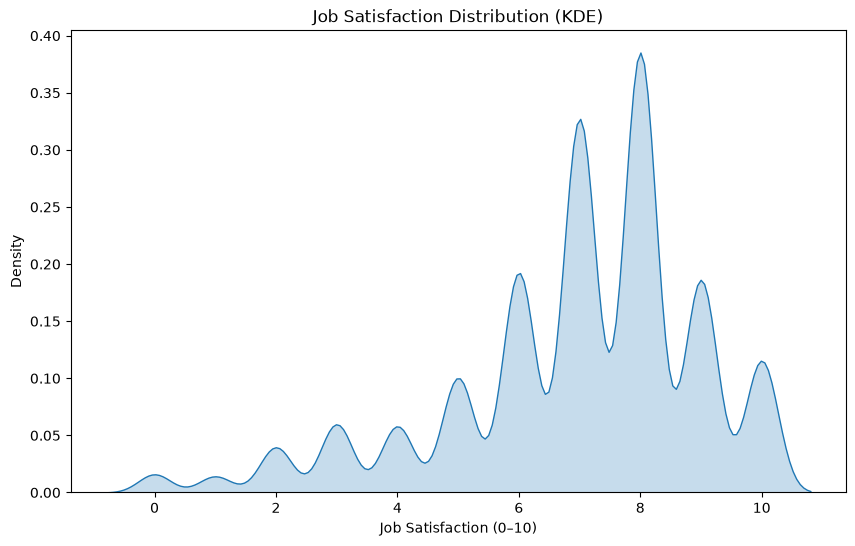

In [6]:
plt.figure(figsize=(10, 6))
sns.kdeplot(df['JobSat'], fill=True)
plt.title('Job Satisfaction Distribution (KDE)')
plt.xlabel('Job Satisfaction (0–10)')
plt.show()

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


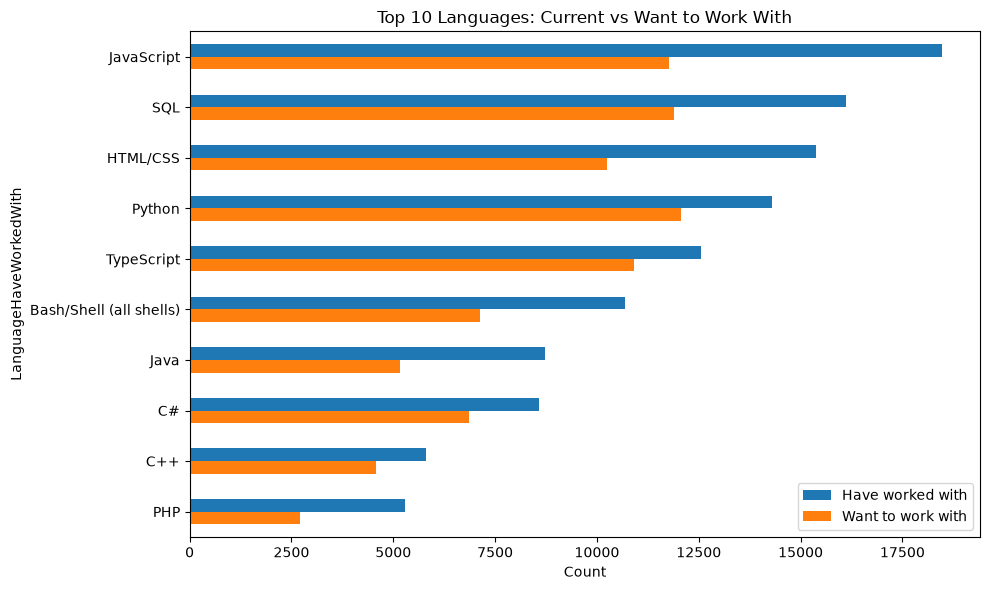

In [7]:
have = df['LanguageHaveWorkedWith'].dropna().str.split(';').explode().value_counts()
want = df['LanguageWantToWorkWith'].dropna().str.split(';').explode().value_counts()
top = have.head(10).index

compare = pd.DataFrame({'Have worked with': have[top], 'Want to work with': want.reindex(top)})
compare.plot(kind='barh', figsize=(10, 6))
plt.gca().invert_yaxis()
plt.title('Top 10 Languages: Current vs Want to Work With')
plt.xlabel('Count')
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


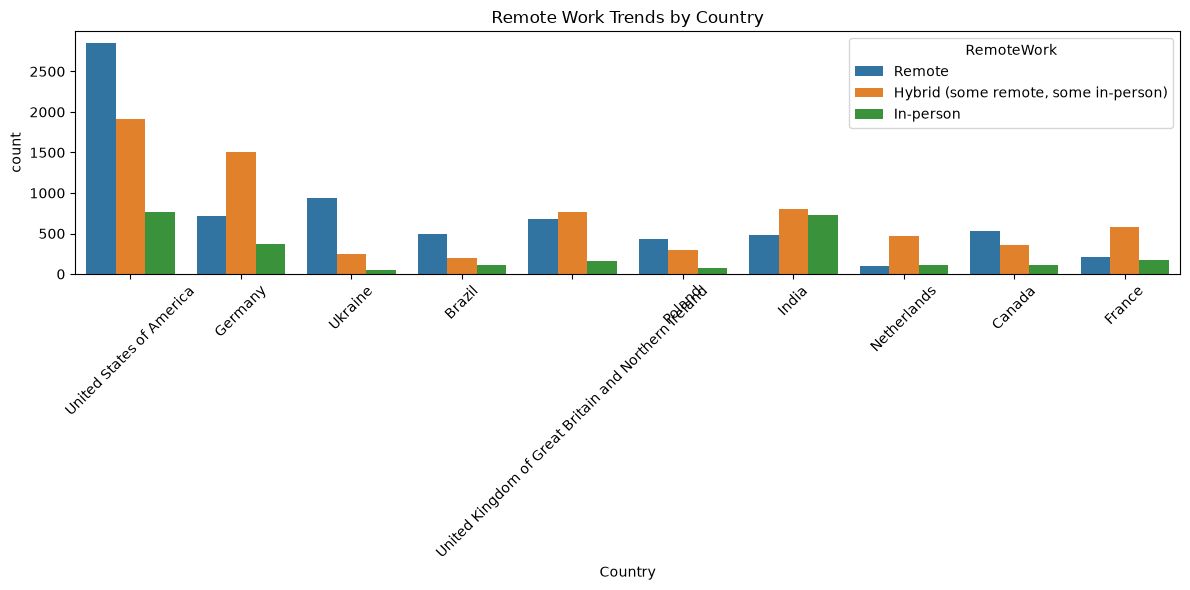

In [8]:
# Top 10 countries by response count
top_countries = df['Country'].value_counts().head(10).index

# Filter data
remote_df = df[df['Country'].isin(top_countries)]

# Grouped count plot
plt.figure(figsize=(12,6))

sns.countplot(
    data=remote_df,
    x='Country',
    hue='RemoteWork'
)

plt.title('Remote Work Trends by Country')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


In [10]:
yc = df['YearsCodePro'].replace({'Less than 1 year': 0, 'More than 50 years': 51})
df['YearsCodePro'] = pd.to_numeric(yc, errors='coerce')

corr_df = df[['YearsCodePro', 'JobSat']].dropna()
print("Pearson: ", corr_df['YearsCodePro'].corr(corr_df['JobSat']))
print("Spearman:", corr_df['YearsCodePro'].rank().corr(corr_df['JobSat'].rank()))

Pearson:  0.10415320964659903
Spearman: 0.11920067409027071


### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


EdLevel                                             Associate degree (A.A., A.S., etc.)  \
Employment                                                                                
Employed, full-time                                                                 817   
Employed, part-time                                                                  62   
Independent contractor, freelancer, or self-emp...                                  135   
Not employed, and not looking for work                                                2   
Not employed, but looking for work                                                    4   
Retired                                                                               1   
Student, full-time                                                                   38   
Student, part-time                                                                   49   

EdLevel                                             Bachelor’s degree (B.A., B.S., B.Eng.

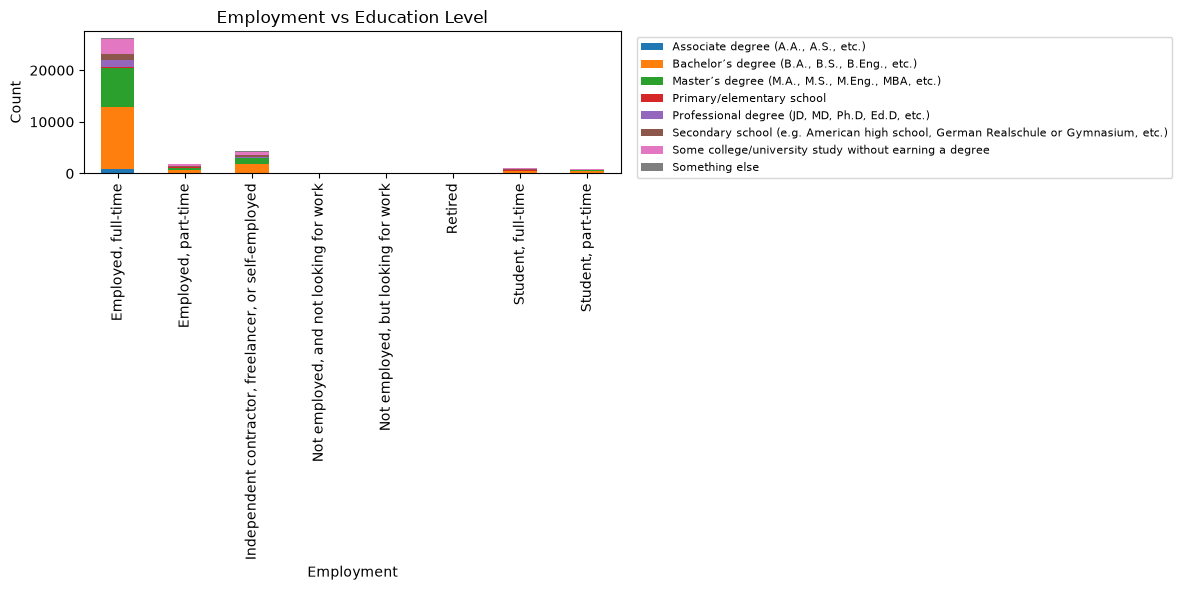

In [11]:
cross_df = df[['Employment', 'EdLevel']].dropna()
cross_df = cross_df.assign(Employment=cross_df['Employment'].str.split(';')).explode('Employment')

cross_tab = pd.crosstab(cross_df['Employment'], cross_df['EdLevel'])
print(cross_tab)

cross_tab.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Employment vs Education Level')
plt.ylabel('Count')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [12]:
df.to_csv('cleaned_survey_data.csv', index=False)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
